In [456]:
# =========================================================
# Import core libraries
# =========================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

from numpy import sqrt
from statsmodels.formula.api import ols
from statsmodels.stats.diagnostic import het_breuschpagan

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

# =========================================================
# Read data
# =========================================================

df = pd.read_csv(
    "Rossmann_100_Complete_Stores.csv",
    low_memory=False
)

In [457]:
# =========================================================
# Inspect the data
# =========================================================

print("First five observations:")
print(df.head())

print("\nData dimensions:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate Store-Date observations:")
print(
    df.duplicated(
        subset=["Store", "Date"]
    ).sum()
)

First five observations:
   Store  DayOfWeek        Date  Sales  Customers  Open  Promo StateHoliday  \
0     16          3  2014-01-01      0          0     0      0            a   
1     38          3  2014-01-01      0          0     0      0            a   
2     80          3  2014-01-01      0          0     0      0            a   
3     85          3  2014-01-01   4184        603     1      0            a   
4    122          3  2014-01-01      0          0     0      0            a   

   SchoolHoliday StoreType Assortment  CompetitionDistance  \
0              1         a          c               3270.0   
1              1         d          a               1090.0   
2              1         d          a               7910.0   
3              1         b          a               1870.0   
4              1         a          c              58260.0   

   CompetitionOpenSinceMonth  CompetitionOpenSinceYear  Promo2  \
0                        NaN                       NaN       

In [458]:
# =========================================================
# Convert and verify Date
# =========================================================

df["Date"] = pd.to_datetime(df["Date"])

print("Minimum date:")
print(df["Date"].min())

print("\nMaximum date:")
print(df["Date"].max())

print("\nNumber of stores:")
print(df["Store"].nunique())

print("\nNumber of daily records per store:")
print(
    df.groupby("Store")["Date"]
    .nunique()
    .value_counts()
)

print("\nObservations by year:")
print(
    df["Date"]
    .dt.year
    .value_counts()
    .sort_index()
)

Minimum date:
2014-01-01 00:00:00

Maximum date:
2015-02-28 00:00:00

Number of stores:
100

Number of daily records per store:
Date
424    100
Name: count, dtype: int64

Observations by year:
Date
2014    36500
2015     5900
Name: count, dtype: int64


In [459]:
# =========================================================
# Basic cleaning
# =========================================================

df["StateHoliday"] = (
    df["StateHoliday"]
    .astype(str)
    .str.strip()
    .replace({
        "0.0": "0"
    })
)

df["DayOfWeek"] = df["DayOfWeek"].astype(int)
df["Store"] = df["Store"].astype(int)
df["Open"] = df["Open"].astype(int)
df["Promo"] = df["Promo"].astype(int)
df["SchoolHoliday"] = df["SchoolHoliday"].astype(int)


# =========================================================
# Month is used as a seasonal control
#
# No TimeTrend or YearTrend is used.
# =========================================================

df["Month"] = df["Date"].dt.month

print(df["Month"].value_counts().sort_index())

Month
1     6200
2     5600
3     3100
4     3000
5     3100
6     3000
7     3100
8     3100
9     3000
10    3100
11    3000
12    3100
Name: count, dtype: int64


In [460]:
# =========================================================
# Create Promo2 start date
# =========================================================

df["Promo2StartDate"] = pd.NaT

valid_promo2_date = (
    df["Promo2SinceYear"].notnull()
    & df["Promo2SinceWeek"].notnull()
)

promo2_date_text = (
    df.loc[
        valid_promo2_date,
        "Promo2SinceYear"
    ]
    .astype(int)
    .astype(str)
    + "-"
    + df.loc[
        valid_promo2_date,
        "Promo2SinceWeek"
    ]
    .astype(int)
    .astype(str)
    .str.zfill(2)
    + "-1"
)

df.loc[
    valid_promo2_date,
    "Promo2StartDate"
] = pd.to_datetime(
    promo2_date_text,
    format="%G-%V-%u",
    errors="coerce"
)

In [461]:
# =========================================================
# Create Promo2Category
#
# Reference category:
# NotActive
#
# Other categories:
# ActivePlanA
# ActivePlanB
# ActivePlanC
# =========================================================

df["Promo2Category"] = "NotActive"

promo2_started = (
    (df["Promo2"] == 1)
    & df["Promo2StartDate"].notnull()
    & (df["Date"] >= df["Promo2StartDate"])
)


# Plan A: January, April, July, October

df.loc[
    promo2_started
    & (
        df["PromoInterval"]
        == "Jan,Apr,Jul,Oct"
    )
    & df["Month"].isin(
        [1, 4, 7, 10]
    ),
    "Promo2Category"
] = "ActivePlanA"


# Plan B: February, May, August, November

df.loc[
    promo2_started
    & (
        df["PromoInterval"]
        == "Feb,May,Aug,Nov"
    )
    & df["Month"].isin(
        [2, 5, 8, 11]
    ),
    "Promo2Category"
] = "ActivePlanB"


# Plan C: March, June, September, December

df.loc[
    promo2_started
    & (
        df["PromoInterval"]
        == "Mar,Jun,Sept,Dec"
    )
    & df["Month"].isin(
        [3, 6, 9, 12]
    ),
    "Promo2Category"
] = "ActivePlanC"


print("Promo2 categories:")
print(
    df["Promo2Category"]
    .value_counts()
)

Promo2 categories:
Promo2Category
NotActive      37116
ActivePlanA     2560
ActivePlanB     1748
ActivePlanC      976
Name: count, dtype: int64


In [462]:
# =========================================================
# Create competition opening date
# =========================================================

df["CompetitionOpenDate"] = pd.to_datetime(
    dict(
        year=df["CompetitionOpenSinceYear"],
        month=df["CompetitionOpenSinceMonth"],
        day=1
    ),
    errors="coerce"
)

In [463]:
# =========================================================
# Chronological split
#
# Training:
# January 1 to December 31, 2014
#
# Testing:
# January 1 to February 28, 2015
# =========================================================

df_train = df[
    df["Date"].dt.year == 2014
].copy()

df_test = df[
    (df["Date"] >= "2015-01-01")
    & (df["Date"] <= "2015-02-28")
].copy()


print("Training period:")
print(
    df_train["Date"].min(),
    "to",
    df_train["Date"].max()
)

print("\nTesting period:")
print(
    df_test["Date"].min(),
    "to",
    df_test["Date"].max()
)

print("\nTraining observations:")
print(df_train.shape[0])

print("\nTesting observations:")
print(df_test.shape[0])

print("\nTraining stores:")
print(df_train["Store"].nunique())

print("\nTesting stores:")
print(df_test["Store"].nunique())

Training period:
2014-01-01 00:00:00 to 2014-12-31 00:00:00

Testing period:
2015-01-01 00:00:00 to 2015-02-28 00:00:00

Training observations:
36500

Testing observations:
5900

Training stores:
100

Testing stores:
100


In [464]:
# =========================================================
# Calculate the Near/Far competition cutoff
#
# Use one observation per training store.
# Do not use test information.
# =========================================================

training_store_distance = (
    df_train[
        [
            "Store",
            "CompetitionDistance"
        ]
    ]
    .drop_duplicates(subset="Store")
)

competition_cutoff = (
    training_store_distance[
        "CompetitionDistance"
    ]
    .dropna()
    .median()
)

print("Training competition-distance cutoff:")
print(competition_cutoff)

Training competition-distance cutoff:
1630.0


In [465]:
# =========================================================
# Create CompetitionExposure for training data
#
# Categories:
# NoActiveCompetitor
# ActiveNear
# ActiveFar
#
# Known distance with missing opening date is treated
# as a pre-existing active competitor.
# =========================================================

df_train["CompetitionExposure"] = (
    "NoActiveCompetitor"
)

known_distance_train = (
    df_train["CompetitionDistance"].notnull()
)

active_or_preexisting_train = (
    known_distance_train
    & (
        df_train["CompetitionOpenDate"].isnull()
        |
        (
            df_train["CompetitionOpenDate"]
            <= df_train["Date"]
        )
    )
)

df_train.loc[
    active_or_preexisting_train
    & (
        df_train["CompetitionDistance"]
        <= competition_cutoff
    ),
    "CompetitionExposure"
] = "ActiveNear"

df_train.loc[
    active_or_preexisting_train
    & (
        df_train["CompetitionDistance"]
        > competition_cutoff
    ),
    "CompetitionExposure"
] = "ActiveFar"

In [466]:
# =========================================================
# Create CompetitionExposure for testing data
#
# Use the training cutoff.
# =========================================================

df_test["CompetitionExposure"] = (
    "NoActiveCompetitor"
)

known_distance_test = (
    df_test["CompetitionDistance"].notnull()
)

active_or_preexisting_test = (
    known_distance_test
    & (
        df_test["CompetitionOpenDate"].isnull()
        |
        (
            df_test["CompetitionOpenDate"]
            <= df_test["Date"]
        )
    )
)

df_test.loc[
    active_or_preexisting_test
    & (
        df_test["CompetitionDistance"]
        <= competition_cutoff
    ),
    "CompetitionExposure"
] = "ActiveNear"

df_test.loc[
    active_or_preexisting_test
    & (
        df_test["CompetitionDistance"]
        > competition_cutoff
    ),
    "CompetitionExposure"
] = "ActiveFar"


print("Training competition categories:")
print(
    df_train["CompetitionExposure"]
    .value_counts()
)

print("\nTesting competition categories:")
print(
    df_test["CompetitionExposure"]
    .value_counts()
)

Training competition categories:
CompetitionExposure
ActiveFar             17734
ActiveNear            17096
NoActiveCompetitor     1670
Name: count, dtype: int64

Testing competition categories:
CompetitionExposure
ActiveFar             2891
ActiveNear            2832
NoActiveCompetitor     177
Name: count, dtype: int64


In [467]:
# =========================================================
# Keep open stores with positive Sales
# =========================================================

df_train = df_train[
    (df_train["Open"] == 1)
    & (df_train["Sales"] > 0)
].copy()

df_test = df_test[
    (df_test["Open"] == 1)
    & (df_test["Sales"] > 0)
].copy()


# =========================================================
# Create LogSales
# =========================================================

df_train["LogSales"] = np.log(
    df_train["Sales"]
)

df_test["LogSales"] = np.log(
    df_test["Sales"]
)


print("Training observations after filtering:")
print(df_train.shape[0])

print("\nTesting observations after filtering:")
print(df_test.shape[0])

Training observations after filtering:
31249

Testing observations after filtering:
5131


### Model without interactions

### This model answers the proposal questions concerning StoreType, Assortment, competition, holidays, weekdays, and promotions.

In [532]:
# =========================================================
# Dependent variable: LogSales
# No C(Store) store fixed effects predictor
# No interaction terms
# =========================================================

model = """
LogSales ~ Promo
+ C(DayOfWeek)
+ SchoolHoliday
+ C(StateHoliday)
+ C(Month)
+ C(StoreType)
+ C(Assortment)
+ C(Promo2Category)
+ C(CompetitionExposure)
"""

model = ols(
    highest_r2_formula,
    data=df_train
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               LogSales   R-squared:                       0.327
Model:                            OLS   Adj. R-squared:                  0.326
Method:                 Least Squares   F-statistic:                     473.4
Date:                Thu, 06 Aug 2026   Prob (F-statistic):               0.00
Time:                        10:25:04   Log-Likelihood:                -13631.
No. Observations:               31249   AIC:                         2.733e+04
Df Residuals:                   31216   BIC:                         2.760e+04
Df Model:                          32                                         
Covariance Type:            nonrobust                                         
                                                   coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

In [533]:
# =========================================================
# adding store fixed-effects model
# No interaction terms
# =========================================================

base = """
LogSales ~ Promo
+ C(DayOfWeek)
+ C(StateHoliday)
+ SchoolHoliday
+ C(Promo2Category)
+ C(CompetitionExposure)
+ C(Month)
+ C(Store)

"""

base = ols(
    base,
    data=df_train
).fit()

print(base.summary())

                            OLS Regression Results                            
Dep. Variable:               LogSales   R-squared:                       0.812
Model:                            OLS   Adj. R-squared:                  0.812
Method:                 Least Squares   F-statistic:                     1069.
Date:                Thu, 06 Aug 2026   Prob (F-statistic):               0.00
Time:                        10:25:32   Log-Likelihood:                 6325.0
No. Observations:               31249   AIC:                        -1.240e+04
Df Residuals:                   31122   BIC:                        -1.134e+04
Df Model:                         126                                         
Covariance Type:            nonrobust                                         
                                                   coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

### Store fixed-effects predictive model (with interactions)

In [474]:
# =========================================================
# Create interaction variables
# =========================================================

for current_df in [df_train, df_test]:

    # -----------------------------------------------------
    # Promo × DayOfWeek
    #
    # Monday is the reference day.
    # Promo_Day6 and Promo_Day7 are not created because
    # there are no promotional observations on those days.
    # -----------------------------------------------------

    current_df["Promo_Day2"] = (
        current_df["Promo"]
        * (current_df["DayOfWeek"] == 2).astype(int)
    )

    current_df["Promo_Day3"] = (
        current_df["Promo"]
        * (current_df["DayOfWeek"] == 3).astype(int)
    )

    current_df["Promo_Day4"] = (
        current_df["Promo"]
        * (current_df["DayOfWeek"] == 4).astype(int)
    )

    current_df["Promo_Day5"] = (
        current_df["Promo"]
        * (current_df["DayOfWeek"] == 5).astype(int)
    )


    # -----------------------------------------------------
    # Promo × StoreType
    #
    # StoreType a is the reference category.
    # -----------------------------------------------------

    current_df["Promo_StoreType_b"] = (
        current_df["Promo"]
        * (current_df["StoreType"] == "b").astype(int)
    )

    current_df["Promo_StoreType_c"] = (
        current_df["Promo"]
        * (current_df["StoreType"] == "c").astype(int)
    )

    current_df["Promo_StoreType_d"] = (
        current_df["Promo"]
        * (current_df["StoreType"] == "d").astype(int)
    )


    # -----------------------------------------------------
    # Promo × Assortment
    #
    # Assortment a is the reference category.
    # -----------------------------------------------------

    current_df["Promo_Assortment_b"] = (
        current_df["Promo"]
        * (current_df["Assortment"] == "b").astype(int)
    )

    current_df["Promo_Assortment_c"] = (
        current_df["Promo"]
        * (current_df["Assortment"] == "c").astype(int)
    )


    # -----------------------------------------------------
    # Competition dummy variables
    #
    # NoActiveCompetitor is the reference category.
    # -----------------------------------------------------

    current_df["Competition_Near"] = (
        current_df["CompetitionExposure"] == "ActiveNear"
    ).astype(int)

    current_df["Competition_Far"] = (
        current_df["CompetitionExposure"] == "ActiveFar"
    ).astype(int)


    # -----------------------------------------------------
    # Promo × CompetitionExposure
    # -----------------------------------------------------

    current_df["Promo_Competition_Near"] = (
        current_df["Promo"]
        * current_df["Competition_Near"]
    )

    current_df["Promo_Competition_Far"] = (
        current_df["Promo"]
        * current_df["Competition_Far"]
    )


    # -----------------------------------------------------
    # Promo × SchoolHoliday
    # -----------------------------------------------------

    current_df["Promo_SchoolHoliday"] = (
        current_df["Promo"]
        * current_df["SchoolHoliday"]
    )


    # -----------------------------------------------------
    # Promo2 dummy variables
    #
    # NotActive is the reference category.
    # -----------------------------------------------------

    current_df["Promo2_A"] = (
        current_df["Promo2Category"] == "ActivePlanA"
    ).astype(int)

    current_df["Promo2_B"] = (
        current_df["Promo2Category"] == "ActivePlanB"
    ).astype(int)

    current_df["Promo2_C"] = (
        current_df["Promo2Category"] == "ActivePlanC"
    ).astype(int)


    # -----------------------------------------------------
    # Promo × Promo2Category
    # -----------------------------------------------------

    current_df["Promo_Promo2_A"] = (
        current_df["Promo"]
        * current_df["Promo2_A"]
    )

    current_df["Promo_Promo2_B"] = (
        current_df["Promo"]
        * current_df["Promo2_B"]
    )

    current_df["Promo_Promo2_C"] = (
        current_df["Promo"]
        * current_df["Promo2_C"]
    )

In [510]:
base_formula = """
LogSales ~ Promo
+ C(DayOfWeek)
+ C(StateHoliday)
+ SchoolHoliday
+ Promo2_A
+ Promo2_B
+ Promo2_C
+ C(CompetitionExposure)
+ C(Month)
+ C(Store)
"""

In [511]:
# =========================================================
# Candidate model formulas
# =========================================================

model_formulas = {

    "Store Fixed-Effects Base":

        base_formula,


    "Store FE + Promo Day Interactions":

        base_formula
        + """
        + Promo_Day2
        + Promo_Day3
        + Promo_Day4
        + Promo_Day5
        """,


    "Store FE + Promo Day + StoreType Interactions":

        base_formula
        + """
        + Promo_Day2
        + Promo_Day3
        + Promo_Day4
        + Promo_Day5
        + Promo_StoreType_b
        + Promo_StoreType_c
        + Promo_StoreType_d
        """,


    "Store FE + Promo Day + StoreType + Assortment Interactions":

        base_formula
        + """
        + Promo_Day2
        + Promo_Day3
        + Promo_Day4
        + Promo_Day5
        + Promo_StoreType_b
        + Promo_StoreType_c
        + Promo_StoreType_d
        + Promo_Assortment_b
        + Promo_Assortment_c
        """,


    "All Business Interactions":

        base_formula
        + """
        + Promo_Day2
        + Promo_Day3
        + Promo_Day4
        + Promo_Day5
        + Promo_StoreType_b
        + Promo_StoreType_c
        + Promo_StoreType_d
        + Promo_Assortment_b
        + Promo_Assortment_c
        + Promo_Competition_Near
        + Promo_Competition_Far
        + Promo_SchoolHoliday
        + Promo_Promo2_A
        + Promo_Promo2_B
        + Promo_Promo2_C
        """
}

In [512]:
# =========================================================
# Compare candidate models
#
# Metrics:
# - Training R2, RMSE, MAE
# - Test R2, RMSE, MAE
# =========================================================

model_results = []

for model_name, formula in model_formulas.items():

    print("\nFitting model:")
    print(model_name)

    model = ols(
        formula,
        data=df_train
    ).fit()

    # Predict LogSales
    predicted_train = model.predict(df_train)
    predicted_test = model.predict(df_test)

    # Training metrics
    train_r2 = r2_score(
        df_train["LogSales"],
        predicted_train
    )

    train_rmse = np.sqrt(
        mean_squared_error(
            df_train["LogSales"],
            predicted_train
        )
    )

    train_mae = mean_absolute_error(
        df_train["LogSales"],
        predicted_train
    )

    # Test metrics
    test_r2 = r2_score(
        df_test["LogSales"],
        predicted_test
    )

    test_rmse = np.sqrt(
        mean_squared_error(
            df_test["LogSales"],
            predicted_test
        )
    )

    test_mae = mean_absolute_error(
        df_test["LogSales"],
        predicted_test
    )

    # Save results
    model_results.append({
        "Model": model_name,
        "Training R2": train_r2,
        "Training RMSE": train_rmse,
        "Training MAE": train_mae,
        "Test R2": test_r2,
        "Test RMSE": test_rmse,
        "Test MAE": test_mae
    })


# =========================================================
# Rank models by Test R2
# =========================================================

model_results = pd.DataFrame(model_results)

model_results = model_results.sort_values(
    by="Test R2",
    ascending=False
).reset_index(drop=True)

display(
    model_results.round(4)
)


Fitting model:
Store Fixed-Effects Base

Fitting model:
Store FE + Promo Day Interactions

Fitting model:
Store FE + Promo Day + StoreType Interactions

Fitting model:
Store FE + Promo Day + StoreType + Assortment Interactions

Fitting model:
All Business Interactions


,Model,Training R2,Training RMSE,Training MAE,Test R2,Test RMSE,Test MAE
0,All Business Interactions,0.8323,0.1868,0.1347,0.8293,0.1851,0.1331
1,Store FE + Promo Day + StoreType + Assortment ...,0.8319,0.1870,0.1349,0.8281,0.1858,0.1337
2,Store FE + Promo Day + StoreType Interactions,0.8275,0.1894,0.1362,0.8229,0.1885,0.1347
3,Store FE + Promo Day Interactions,0.8197,0.1937,0.1391,0.8167,0.1918,0.1373
4,Store Fixed-Effects Base,0.8123,0.1976,0.1438,0.8091,0.1958,0.1425


In [516]:
# =========================================================
# Final model: All Business Interactions
#
# Dependent variable: LogSales
# Training data: 2014
# Test data: January-February 2015
# =========================================================

final_formula = """
LogSales ~ Promo
+ C(DayOfWeek)
+ C(StateHoliday)
+ SchoolHoliday
+ C(Promo2Category)
+ C(CompetitionExposure) 
+ C(Month)
+ C(Store)
+ Promo_Day2
+ Promo_Day3
+ Promo_Day4
+ Promo_Day5
+ Promo_StoreType_b
+ Promo_StoreType_c
+ Promo_StoreType_d
+ Promo_Assortment_b
+ Promo_Assortment_c
+ Promo_Competition_Near
+ Promo_Competition_Far
+ Promo_SchoolHoliday
+ Promo_Promo2_A
+ Promo_Promo2_B
+ Promo_Promo2_C
"""


# =========================================================
# Fit the final model using 2014 training data
# =========================================================

final_model = ols(
    final_formula,
    data=df_train
).fit()


# =========================================================
# Display regression results
# =========================================================

print(final_model.summary())

                            OLS Regression Results                            
Dep. Variable:               LogSales   R-squared:                       0.832
Model:                            OLS   Adj. R-squared:                  0.832
Method:                 Least Squares   F-statistic:                     1095.
Date:                Wed, 05 Aug 2026   Prob (F-statistic):               0.00
Time:                        08:11:14   Log-Likelihood:                 8086.1
No. Observations:               31249   AIC:                        -1.589e+04
Df Residuals:                   31107   BIC:                        -1.470e+04
Df Model:                         141                                         
Covariance Type:            nonrobust                                         
                                                   coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

# Homoscedasticity

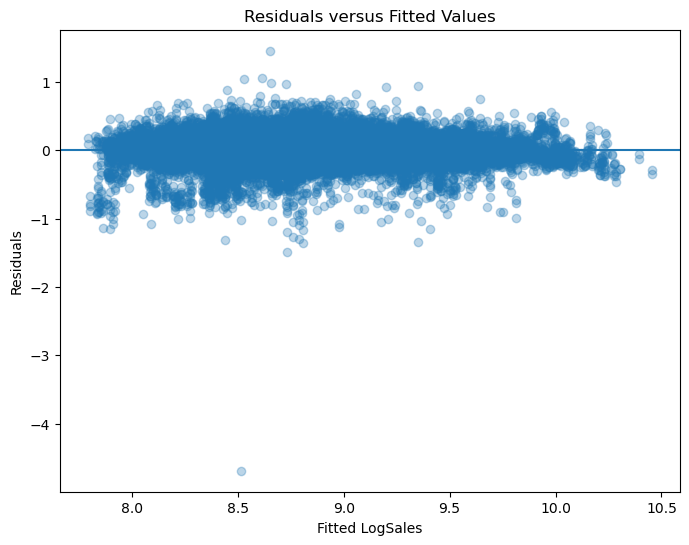

In [479]:
# =========================================================
# Residuals versus fitted values
# =========================================================

fitted_values = final_model.fittedvalues
residuals = final_model.resid

plt.figure(figsize=(8, 6))

plt.scatter(
    fitted_values,
    residuals,
    alpha=0.3
)

plt.axhline(y=0)

plt.xlabel("Fitted LogSales")
plt.ylabel("Residuals")
plt.title("Residuals versus Fitted Values")
plt.show()

### residuals randomly distributed around zero, no curved, funnel-shaped pattern.However, the residual spread is not constant:variability becomes narrower at higher fitted values;there is at least one unusually large negative residual. This visual pattern suggests heteroskedasticity and possible outliers.

In [480]:
# =========================================================
# Breusch-Pagan test
# =========================================================

print("""
H0: The residual variance is constant.
The errors are homoskedastic.

H1: The residual variance is not constant.
The errors are heteroskedastic.
""")

bp_test = het_breuschpagan(
    final_model.resid,
    final_model.model.exog
)

bp_results = pd.Series(
    bp_test,
    index=[
        "LM Statistic",
        "LM p-value",
        "F Statistic",
        "F p-value"
    ]
)

print(bp_results)


H0: The residual variance is constant.
The errors are homoskedastic.

H1: The residual variance is not constant.
The errors are heteroskedastic.

LM Statistic    2141.001422
LM p-value         0.000000
F Statistic       16.227201
F p-value          0.000000
dtype: float64


### Because the p-value is below 0.05, reject null hypothesis. There is strong evidence that the model errors are heteroskedastic.

In [481]:
# =========================================================
# Final model with HC3 robust standard errors
# =========================================================

final_model_hc3 = ols(
    final_formula,
    data=df_train
).fit(
    cov_type="HC3"
)

print(
    final_model_hc3.summary()
)

                            OLS Regression Results                            
Dep. Variable:               LogSales   R-squared:                       0.832
Model:                            OLS   Adj. R-squared:                  0.832
Method:                 Least Squares   F-statistic:                     1461.
Date:                Sun, 02 Aug 2026   Prob (F-statistic):               0.00
Time:                        18:55:08   Log-Likelihood:                 8086.1
No. Observations:               31249   AIC:                        -1.589e+04
Df Residuals:                   31107   BIC:                        -1.470e+04
Df Model:                         141                                         
Covariance Type:                  HC3                                         
                                                   coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

In [517]:
# =========================================================
# Test 1: Individual-store effects
# =========================================================

print("""
H0: All individual-store coefficients are jointly zero.

H1: At least one individual-store coefficient is non-zero.
""")

store_terms = [
    coefficient
    for coefficient in final_model_hc3.params.index
    if coefficient.startswith("C(Store)[T.")
]

store_hypothesis = ", ".join([
    coefficient + " = 0"
    for coefficient in store_terms
])

store_test = final_model_hc3.wald_test(
    store_hypothesis,
    scalar=True
)

print(store_test)


H0: All individual-store coefficients are jointly zero.

H1: At least one individual-store coefficient is non-zero.

<Wald test (chi2): statistic=133806.7926852663, p-value=0.0, df_denom=99>


In [503]:
# =========================================================
# Test 2: overall regular promotion effect
# =========================================================

print("""
H0: Promo and all Promo interaction coefficients
are jointly equal to zero.

H1: At least one promotion-related coefficient
is not equal to zero.
""")

promotion_hypothesis = """
(
Promo = 0,
Promo_Day2 = 0,
Promo_Day3 = 0,
Promo_Day4 = 0,
Promo_Day5 = 0,
Promo_StoreType_b = 0,
Promo_StoreType_c = 0,
Promo_StoreType_d = 0,
Promo_Assortment_b = 0,
Promo_Assortment_c = 0,
Promo_Competition_Near = 0,
Promo_Competition_Far = 0,
Promo_SchoolHoliday = 0,
Promo_Promo2_A = 0,
Promo_Promo2_B = 0,
Promo_Promo2_C = 0
)
"""

promotion_test = final_model_hc3.wald_test(
    promotion_hypothesis,
    scalar=True
)

print(promotion_test)


H0: Promo and all Promo interaction coefficients
are jointly equal to zero.

H1: At least one promotion-related coefficient
is not equal to zero.

<Wald test (chi2): statistic=28878.96767509028, p-value=0.0, df_denom=16>


In [518]:
# =========================================================
# Test 3: Weekday and Promo × Weekday effects
# =========================================================

print("""
H0: All weekday main-effect and Promo × Weekday
coefficients are jointly zero.

H1: At least one weekday-related coefficient is non-zero.
""")

weekday_hypothesis = """
C(DayOfWeek)[T.2] = 0,
C(DayOfWeek)[T.3] = 0,
C(DayOfWeek)[T.4] = 0,
C(DayOfWeek)[T.5] = 0,
C(DayOfWeek)[T.6] = 0,
C(DayOfWeek)[T.7] = 0,
Promo_Day2 = 0,
Promo_Day3 = 0,
Promo_Day4 = 0,
Promo_Day5 = 0
"""

weekday_test = final_model_hc3.wald_test(
    weekday_hypothesis,
    scalar=True
)

print(weekday_test)


H0: All weekday main-effect and Promo × Weekday
coefficients are jointly zero.

H1: At least one weekday-related coefficient is non-zero.

<Wald test (chi2): statistic=6189.105714353921, p-value=0.0, df_denom=10>


In [519]:
# =========================================================
# Test 3A: Promo effectiveness varies by weekday
# =========================================================

print("""
H0: All Promo × Weekday interaction coefficients are zero.

H1: At least one Promo × Weekday coefficient is non-zero.
""")

promo_weekday_hypothesis = """
Promo_Day2 = 0,
Promo_Day3 = 0,
Promo_Day4 = 0,
Promo_Day5 = 0
"""

promo_weekday_test = final_model_hc3.wald_test(
    promo_weekday_hypothesis,
    scalar=True
)

print(promo_weekday_test)


H0: All Promo × Weekday interaction coefficients are zero.

H1: At least one Promo × Weekday coefficient is non-zero.

<Wald test (chi2): statistic=1994.4920564251092, p-value=0.0, df_denom=4>


In [528]:
# =========================================================
# Promo2 and Promo × Promo2
# =========================================================

print("""
H0: All Promo2 main-effect and Promo × Promo2
coefficients are jointly zero.

H1: At least one Promo2-related coefficient is non-zero.
""")

promo2_terms = [
    coefficient
    for coefficient in final_model_hc3.params.index
    if coefficient.startswith("C(Promo2Category)[T.")
]

promo2_interaction_terms = [
    "Promo_Promo2_A",
    "Promo_Promo2_B",
    "Promo_Promo2_C"
]

promo2_test_terms = promo2_terms + [
    coefficient
    for coefficient in promo2_interaction_terms
    if coefficient in final_model_hc3.params.index
]

promo2_hypothesis = ", ".join([
    coefficient + " = 0"
    for coefficient in promo2_test_terms
])

promo2_test = final_model_hc3.wald_test(
    promo2_hypothesis,
    scalar=True
)

print(promo2_test)


H0: All Promo2 main-effect and Promo × Promo2
coefficients are jointly zero.

H1: At least one Promo2-related coefficient is non-zero.

<Wald test (chi2): statistic=82.93608279964181, p-value=8.830669851817298e-16, df_denom=6>


In [520]:
# =========================================================
# Test 4: Promo effectiveness by StoreType
# =========================================================

print("""
H0: All Promo × StoreType interaction coefficients are zero.

H1: Promotion effectiveness differs for at least
one StoreType.
""")

storetype_hypothesis = """
Promo_StoreType_b = 0,
Promo_StoreType_c = 0,
Promo_StoreType_d = 0
"""

storetype_test = final_model_hc3.wald_test(
    storetype_hypothesis,
    scalar=True
)

print(storetype_test)


H0: All Promo × StoreType interaction coefficients are zero.

H1: Promotion effectiveness differs for at least
one StoreType.

<Wald test (chi2): statistic=635.9492760550448, p-value=1.6206973556239205e-137, df_denom=3>


In [521]:
# =========================================================
# Test 5: Promo effectiveness by Assortment
# =========================================================

print("""
H0: All Promo × Assortment interaction coefficients are zero.

H1: Promotion effectiveness differs for at least
one Assortment category.
""")

assortment_hypothesis = """
Promo_Assortment_b = 0,
Promo_Assortment_c = 0
"""

assortment_test = final_model_hc3.wald_test(
    assortment_hypothesis,
    scalar=True
)

print(assortment_test)


H0: All Promo × Assortment interaction coefficients are zero.

H1: Promotion effectiveness differs for at least
one Assortment category.

<Wald test (chi2): statistic=826.2494694216795, p-value=3.8212669429464332e-180, df_denom=2>


In [522]:
# =========================================================
# Test 6: Month effects
# =========================================================

print("""
H0: All month coefficients are jointly zero.

H1: At least one month coefficient is non-zero.
""")

month_terms = [
    coefficient
    for coefficient in final_model_hc3.params.index
    if coefficient.startswith("C(Month)[T.")
]

month_hypothesis = ", ".join([
    coefficient + " = 0"
    for coefficient in month_terms
])

month_test = final_model_hc3.wald_test(
    month_hypothesis,
    scalar=True
)

print(month_test)


H0: All month coefficients are jointly zero.

H1: At least one month coefficient is non-zero.

<Wald test (chi2): statistic=2729.26799616201, p-value=0.0, df_denom=11>


In [523]:
# =========================================================
# Test 7: StateHoliday effects
# =========================================================

print("""
H0: All StateHoliday coefficients are jointly zero.

H1: At least one StateHoliday coefficient is non-zero.
""")

state_holiday_hypothesis = """
C(StateHoliday)[T.a] = 0,
C(StateHoliday)[T.b] = 0,
C(StateHoliday)[T.c] = 0
"""

state_holiday_test = final_model_hc3.wald_test(
    state_holiday_hypothesis,
    scalar=True
)

print(state_holiday_test)


H0: All StateHoliday coefficients are jointly zero.

H1: At least one StateHoliday coefficient is non-zero.

<Wald test (chi2): statistic=35.529653945165826, p-value=9.414862581178952e-08, df_denom=3>


In [524]:
# =========================================================
# Test 8: SchoolHoliday and Promo × SchoolHoliday
# =========================================================

print("""
H0: SchoolHoliday and Promo × SchoolHoliday
coefficients are jointly zero.

H1: At least one school-holiday-related coefficient
is non-zero.
""")

school_holiday_hypothesis = """
SchoolHoliday = 0,
Promo_SchoolHoliday = 0
"""

school_holiday_test = final_model_hc3.wald_test(
    school_holiday_hypothesis,
    scalar=True
)

print(school_holiday_test)


H0: SchoolHoliday and Promo × SchoolHoliday
coefficients are jointly zero.

H1: At least one school-holiday-related coefficient
is non-zero.

<Wald test (chi2): statistic=11.103842643199647, p-value=0.003879995358541647, df_denom=2>


In [529]:
# =========================================================
# Test 9: competition exposure
# =========================================================

print("""
H0: Competition effects and Promo × competition
interaction effects are jointly equal to zero.

H1: At least one competition-related coefficient
is not equal to zero.
""")

competition_hypothesis = """
(
C(CompetitionExposure)[T.ActiveNear] = 0,
C(CompetitionExposure)[T.NoActiveCompetitor] = 0,
Promo_Competition_Near = 0,
Promo_Competition_Far = 0
)
"""

competition_test = final_model_hc3.wald_test(
    competition_hypothesis,
    scalar=True
)

print(competition_test)


H0: Competition effects and Promo × competition
interaction effects are jointly equal to zero.

H1: At least one competition-related coefficient
is not equal to zero.

<Wald test (chi2): statistic=4.046925547701847, p-value=0.3996924168832055, df_denom=4>


In [531]:
# =========================================================
# Summarize joint Wald-test results
# =========================================================

wald_results = pd.DataFrame({

    "Test": [
        "Individual-store effects",
        "Overall regular promotion",
        "Weekday and Promo x Weekday",
        "Promo x Weekday only",
        "Promo x StoreType",
        "Promo x Assortment",
        "Month",
        "StateHoliday",
        "SchoolHoliday and interaction",
        "Competition and interactions",
        "Promo2 and interactions"
    ],

    "Wald Statistic": [
        float(store_test.statistic),
        float(promotion_test.statistic),
        float(weekday_test.statistic),
        float(promo_weekday_test.statistic),
        float(storetype_test.statistic),
        float(assortment_test.statistic),
        float(month_test.statistic),
        float(state_holiday_test.statistic),
        float(school_holiday_test.statistic),
        float(competition_test.statistic),
        float(promo2_test.statistic)
    ],

    "p-value": [
        float(store_test.pvalue),
        float(promotion_test.pvalue),
        float(weekday_test.pvalue),
        float(promo_weekday_test.pvalue),
        float(storetype_test.pvalue),
        float(assortment_test.pvalue),
        float(month_test.pvalue),
        float(state_holiday_test.pvalue),
        float(school_holiday_test.pvalue),
        float(competition_test.pvalue),
        float(promo2_test.pvalue)
    ]
})

wald_results["Decision at 5%"] = np.where(
    wald_results["p-value"] < 0.05,
    "Reject H0",
    "Fail to reject H0"
)

display(
    wald_results.round(4)
)

,Test,Wald Statistic,p-value,Decision at 5%
0,Individual-store effects,133806.7927,0.0000,Reject H0
1,Overall regular promotion,28878.9677,0.0000,Reject H0
2,Weekday and Promo x Weekday,6189.1057,0.0000,Reject H0
3,Promo x Weekday only,1994.4921,0.0000,Reject H0
4,Promo x StoreType,635.9493,0.0000,Reject H0
5,Promo x Assortment,826.2495,0.0000,Reject H0
6,Month,2729.2680,0.0000,Reject H0
7,StateHoliday,35.5297,0.0000,Reject H0
8,SchoolHoliday and interaction,11.1038,0.0039,Reject H0
9,Competition and interactions,4.0469,0.3997,Fail to reject H0


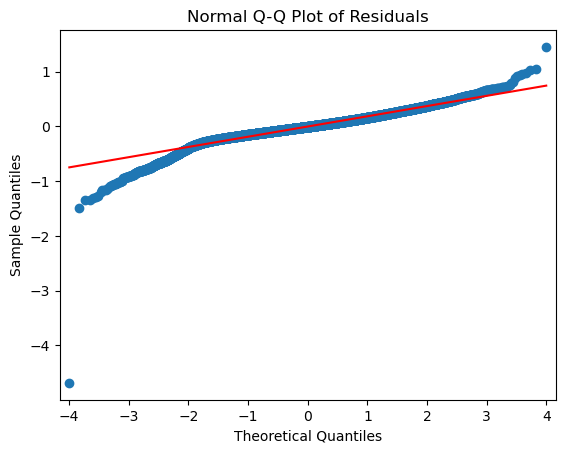

In [483]:
# =========================================================
# Normal Q-Q plot of residuals
# =========================================================

import statsmodels.api as sm

sm.qqplot(
    final_model.resid,
    line="s"
)

plt.title("Normal Q-Q Plot of Residuals")
plt.show()

### The normality assumption is not fully satisfied. Although the central portion of the residual distribution is approximately normal, substantial deviations occur in both tails, particularly the lower tail. This indicates heavy tails and extreme observations. Do not automatically delete the outliers. Review whether they are data errors or valid unusual business events. Because the training sample is very large, this non-normality is less concerning for large-sample inference.

### The Q–Q plot shows that most residuals near the centre follow the normal reference line reasonably well. However, the residuals deviate from the line in both tails, with one particularly extreme negative residual. Therefore, the residuals are not perfectly normally distributed and exhibit heavy tails. Given the large sample size, the model’s inference is less dependent on exact residual normality, while HC3 robust standard errors are used to address heteroskedasticity. Extreme observations are reviewed using studentized residuals and Cook’s distance rather than removed automatically.

# Outlier and Influential observations

In [502]:
# =========================================================
# Potential outliers
#
# Rule:
# |studentized residual| > 2
# =========================================================

outliers = influence_table[
    abs(
        influence_table["StudentizedResidual"]
    ) > 2
].copy()

print("Potential outliers:")
print(len(outliers))

display(
    outliers
    .sort_values(
        "StudentizedResidual",
        key=abs,
        ascending=False
    )
    .head(10)
)

Potential outliers:
1490


,Store,Date,Sales,LogSales,Promo,StudentizedResidual,Leverage,CooksDistance
32557,652,2014-11-22,46,3.828641,0,-25.080607,0.003932,0.017489
8104,122,2014-03-23,1407,7.249215,0,-7.934322,0.004616,0.002056
25205,123,2014-09-10,24549,10.108426,0,7.783952,0.004311,0.001847
9504,122,2014-04-06,1729,7.455298,0,-7.230489,0.004652,0.001721
22,335,2014-01-01,3007,8.008698,0,-7.207239,0.014004,0.005195
29094,1081,2014-10-18,1252,7.132498,0,-6.998955,0.003558,0.001232
13004,122,2014-05-11,1799,7.494986,0,-6.921437,0.004634,0.001571
29104,122,2014-10-19,1792,7.491088,0,-6.786899,0.004625,0.001507
8804,122,2014-03-30,1879,7.538495,0,-6.385682,0.004616,0.001332
11604,122,2014-04-27,2079,7.639642,0,-6.243600,0.004652,0.001283


In [501]:
# =========================================================
# Potentially influential observations
# =========================================================

n = len(influence_table)

cooks_cutoff = 4 / n

influential = influence_table[
    influence_table["CooksDistance"]
    > cooks_cutoff
].copy()

print("Cook's-distance cutoff:")
print(cooks_cutoff)

print("\nPotentially influential observations:")
print(len(influential))

display(
    influential
    .sort_values(
        "CooksDistance",
        ascending=False
    )
    .head(10)
)

Cook's-distance cutoff:
0.0001280040961310762

Potentially influential observations:
1507


,Store,Date,Sales,LogSales,Promo,StudentizedResidual,Leverage,CooksDistance
32557,652,2014-11-22,46,3.828641,0,-25.080607,0.003932,0.017489
35822,335,2014-12-25,4146,8.329899,0,-5.628395,0.034233,0.007908
10722,335,2014-04-18,6983,8.851234,1,-4.887126,0.034701,0.006046
22,335,2014-01-01,3007,8.008698,0,-7.207239,0.014004,0.005195
35922,335,2014-12-26,5784,8.662851,0,-4.314833,0.034232,0.004647
35861,682,2014-12-25,4696,8.454466,0,-4.006211,0.034158,0.003997
30334,479,2014-10-31,3822,8.248529,0,-6.223225,0.014268,0.003948
10794,1081,2014-04-18,3883,8.264363,1,-3.827693,0.033710,0.003599
11022,335,2014-04-21,6476,8.775858,0,-3.764067,0.034182,0.003531
11004,122,2014-04-21,3399,8.131237,0,-3.566119,0.033667,0.003120


### The Cook’s-distance screening rule identified 1,507 observations above 4/n. Because the sample is large, this threshold is very small and should be treated as a review criterion rather than an automatic deletion rule. The largest Cook’s distance was approximately 0.0175, well below 1, indicating that no single observation had overwhelming influence on the model. Several observations had extreme studentized residuals, including Store 652 on November 22, 2014. These observations were investigated and a sensitivity model was estimated excluding observations that were both extreme outliers and above the Cook’s-distance threshold. The final decision to retain or exclude them should depend on data validity and whether the substantive results materially change.

In [486]:
# =========================================================
# Predict LogSales
# =========================================================

predicted_train_log_sales = final_model.predict(
    df_train
)

predicted_test_log_sales = final_model.predict(
    df_test
)


# =========================================================
# Training metrics on LogSales
# =========================================================

training_r2 = r2_score(
    df_train["LogSales"],
    predicted_train_log_sales
)

training_rmse = np.sqrt(
    mean_squared_error(
        df_train["LogSales"],
        predicted_train_log_sales
    )
)

training_mae = mean_absolute_error(
    df_train["LogSales"],
    predicted_train_log_sales
)


# =========================================================
# Test metrics on LogSales
# =========================================================

test_r2 = r2_score(
    df_test["LogSales"],
    predicted_test_log_sales
)

test_rmse = np.sqrt(
    mean_squared_error(
        df_test["LogSales"],
        predicted_test_log_sales
    )
)

test_mae = mean_absolute_error(
    df_test["LogSales"],
    predicted_test_log_sales
)


# =========================================================
# Display final-model performance
# =========================================================

final_model_results = pd.DataFrame({
    "Model": [
        "All Business Interactions"
    ],
    "Training R2": [
        training_r2
    ],
    "Training RMSE": [
        training_rmse
    ],
    "Training MAE": [
        training_mae
    ],
    "Test R2": [
        test_r2
    ],
    "Test RMSE": [
        test_rmse
    ],
    "Test MAE": [
        test_mae
    ]
})

display(final_model_results.round(4))

,Model,Training R2,Training RMSE,Training MAE,Test R2,Test RMSE,Test MAE
0,All Business Interactions,0.8323,0.1868,0.1347,0.8293,0.1851,0.1331


       Actual LogSales  Predicted LogSales  Residual
36503         8.428581            8.861257 -0.432677
36515         9.247347            9.481838 -0.234491
36516         9.932124            9.925378  0.006745
36517         8.162231            8.349752 -0.187521
36522         8.139732            9.420552 -1.280820


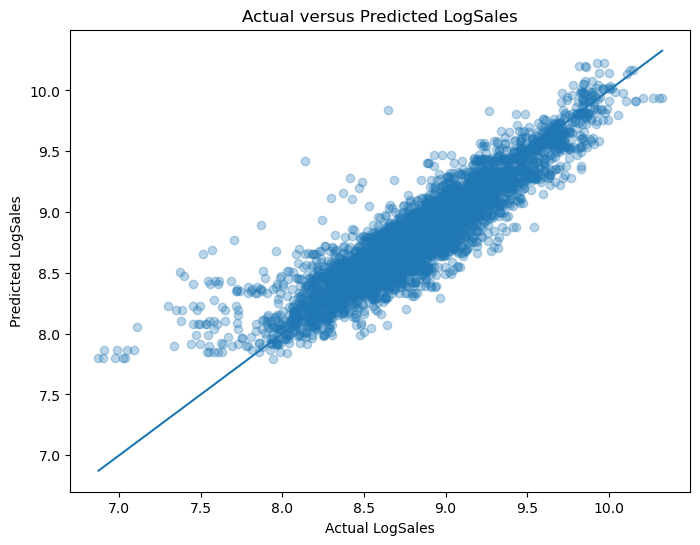

In [487]:
# =========================================================
# Predict LogSales using the final model
# =========================================================

predicted_log_sales = final_model.predict(df_test)


# =========================================================
# Compare actual and predicted LogSales
# =========================================================

log_sales_comparison = pd.DataFrame({
    "Actual LogSales": df_test["LogSales"],
    "Predicted LogSales": predicted_log_sales
})

log_sales_comparison["Residual"] = (
    log_sales_comparison["Actual LogSales"]
    - log_sales_comparison["Predicted LogSales"]
)

print(log_sales_comparison.head())


# =========================================================
# Plot actual versus predicted LogSales
# =========================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    df_test["LogSales"],
    predicted_log_sales,
    alpha=0.3
)

minimum_log_value = min(
    df_test["LogSales"].min(),
    predicted_log_sales.min()
)

maximum_log_value = max(
    df_test["LogSales"].max(),
    predicted_log_sales.max()
)

plt.plot(
    [minimum_log_value, maximum_log_value],
    [minimum_log_value, maximum_log_value]
)

plt.xlabel("Actual LogSales")
plt.ylabel("Predicted LogSales")
plt.title("Actual versus Predicted LogSales")
plt.show()

In [493]:
# =========================================================
# Predictions and 95% confidence interval on Sales scale
# =========================================================

prediction_output = final_model.get_prediction(
    df_test
).summary_frame(alpha=0.01)

final_predictions = df_test[
    ["Store", "Date", "Sales", "LogSales"]
].copy()

final_predictions["PredictedLogSales"] = (
    prediction_output["mean"].values
)

final_predictions["PredictedSales"] = np.exp(
    final_predictions["PredictedLogSales"]
)

final_predictions["Sales_CI_Lower"] = np.exp(
    prediction_output["mean_ci_lower"].values
)

final_predictions["Sales_CI_Upper"] = np.exp(
    prediction_output["mean_ci_upper"].values
)

final_predictions["SalesResidual"] = (
    final_predictions["Sales"]
    - final_predictions["PredictedSales"]
)

display(final_predictions.head(10))

,Store,Date,Sales,LogSales,PredictedLogSales,PredictedSales,Sales_CI_Lower,Sales_CI_Upper,SalesResidual
36503,85,2015-01-01,4576,8.428581,8.861257,7053.345307,6669.086300,7459.744527,-2477.345307
36515,259,2015-01-01,10377,9.247347,9.481838,13119.277284,12407.521863,13871.862435,-2742.277284
36516,262,2015-01-01,20581,9.932124,9.925378,20442.641852,19331.908696,21617.193235,138.358148
36517,274,2015-01-01,3506,8.162231,8.349752,4229.130000,3993.758835,4478.372704,-723.130000
36522,335,2015-01-01,3428,8.139732,9.420552,12339.393876,11655.085579,13063.880158,-8911.393876
36524,353,2015-01-01,5383,8.591001,8.768561,6428.914434,6079.818692,6798.054827,-1045.914434
36530,423,2015-01-01,9997,9.210040,9.263864,10549.823542,9957.543295,11177.332949,-552.823542
36537,494,2015-01-01,3802,8.243283,8.937584,7612.781436,7199.192875,8050.130369,-3810.781436
36547,562,2015-01-01,10552,9.264071,9.832597,18631.273284,17617.858780,19702.981419,-8079.273284
36559,676,2015-01-01,6678,8.806574,9.065016,8647.421494,8178.276053,9143.479384,-1969.421494


### model performs well for normal operating days but does not fully capture extreme demand events.

In [513]:
# =========================================================
# Construct 95% and 99% prediction intervals
# =========================================================

prediction_95 = final_model_hc3.get_prediction(
    df_test
).summary_frame(alpha=0.05)

prediction_99 = final_model_hc3.get_prediction(
    df_test
).summary_frame(alpha=0.01)


final_predictions = df_test[
    ["Store", "Date", "Sales", "LogSales"]
].copy()

final_predictions["PredictedSales"] = np.exp(
    prediction_95["mean"].values
)

final_predictions["PI95_Lower"] = np.exp(
    prediction_95["obs_ci_lower"].values
)

final_predictions["PI95_Upper"] = np.exp(
    prediction_95["obs_ci_upper"].values
)

final_predictions["PI99_Lower"] = np.exp(
    prediction_99["obs_ci_lower"].values
)

final_predictions["PI99_Upper"] = np.exp(
    prediction_99["obs_ci_upper"].values
)

In [514]:
# =========================================================
# Display 10 prediction cases
# =========================================================

prediction_cases = final_predictions.sample(
    n=10,
    random_state=860
).sort_values("Sales").reset_index(drop=True)

display(
    prediction_cases[
        [
            "Store",
            "Date",
            "Sales",
            "PredictedSales",
            "PI95_Lower",
            "PI95_Upper",
            "PI99_Lower",
            "PI99_Upper"
        ]
    ].round(2)
)

,Store,Date,Sales,PredictedSales,PI95_Lower,PI95_Upper,PI99_Lower,PI99_Upper
0,1088,2015-02-25,4298,3663.97,2536.81,5291.96,2260.05,5940.01
1,686,2015-01-20,5573,4431.95,3065.83,6406.82,2730.60,7193.38
2,1103,2015-02-21,5823,4166.90,2884.21,6020.04,2569.32,6757.85
3,686,2015-02-26,5870,4562.41,3156.08,6595.39,2810.98,7405.10
4,865,2015-02-24,6709,6454.00,4467.62,9323.56,3979.96,10465.98
5,648,2015-01-17,7134,4991.46,3456.54,7207.98,3079.61,8090.20
6,648,2015-01-28,7291,7111.98,4925.26,10269.57,4388.25,11526.31
7,502,2015-02-21,7768,8006.76,5543.67,11564.21,4938.88,12980.29
8,733,2015-01-07,13852,13936.32,9651.93,20122.50,8599.74,22584.53
9,560,2015-01-28,13853,13475.08,9330.23,19461.24,8312.47,21844.03


In [515]:
# =========================================================
# Check prediction-interval coverage
# =========================================================

coverage_95 = (
    (
        final_predictions["Sales"]
        >= final_predictions["PI95_Lower"]
    )
    &
    (
        final_predictions["Sales"]
        <= final_predictions["PI95_Upper"]
    )
).mean() * 100

coverage_99 = (
    (
        final_predictions["Sales"]
        >= final_predictions["PI99_Lower"]
    )
    &
    (
        final_predictions["Sales"]
        <= final_predictions["PI99_Upper"]
    )
).mean() * 100

coverage_results = pd.DataFrame({
    "Prediction Interval": [
        "95% PI",
        "99% PI"
    ],
    "Actual Sales Within Interval (%)": [
        coverage_95,
        coverage_99
    ]
})

display(coverage_results.round(2))

,Prediction Interval,Actual Sales Within Interval (%)
0,95% PI,95.30
1,99% PI,97.74
